# Lab 2 — Ad Click Prediction (CTR)

**Task checklist**
1. Train a CTR model
2. Evaluate using ROC-AUC + calibration
3. Explain business tradeoffs (false positives vs false negatives)

**Dataset**: [OpenML `Click_prediction_small`](https://www.openml.org/d/42733) — ~400k ad impressions from a sponsored-search engine, with a `click` label for each impression. The notebook downloads it automatically (≈29 MB).

**Approach**: gradient-boosted trees on categorical IDs (ad, advertiser, query, keyword, …) + numeric `depth`/`position`, compared against a logistic-regression baseline. We then look at *calibration*, which matters more than AUC for the ad-auction use case.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (brier_score_loss, confusion_matrix, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

DATA_URL = ("https://raw.githubusercontent.com/datasets/openml-datasets/"
            "master/data/Click_prediction_small/Click_prediction_small.csv")
DATA_PATH = os.path.join("data", "Click_prediction_small.csv")

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(399482, 12)


,click,impression,url_hash,ad_id,advertiser_id,depth,position,query_id,keyword_id,title_id,description_id,user_id
0,0,1,1.071003e+19,8343295,11700,3,3,7702266,21264,27892,1559,0
1,1,1,1.736385e+19,20017077,23798,1,1,93079,35498,4,36476,562934
2,0,1,8.915473e+18,21348354,36654,1,1,10981,19975,36105,33292,11621116
3,0,1,4.426693e+18,20366086,33280,3,3,0,5942,4057,4390,8778348
4,0,1,1.157260e+19,6803526,10790,2,1,9881978,60593,25242,1679,12118311


## 1. Quick EDA

rows: 399482 | CTR: 0.1679
click                  2
impression           327
url_hash           15787
ad_id              82778
advertiser_id      11955
depth                  3
position               3
query_id          248486
keyword_id         93414
title_id          155012
description_id    129271
user_id           287967
dtype: int64


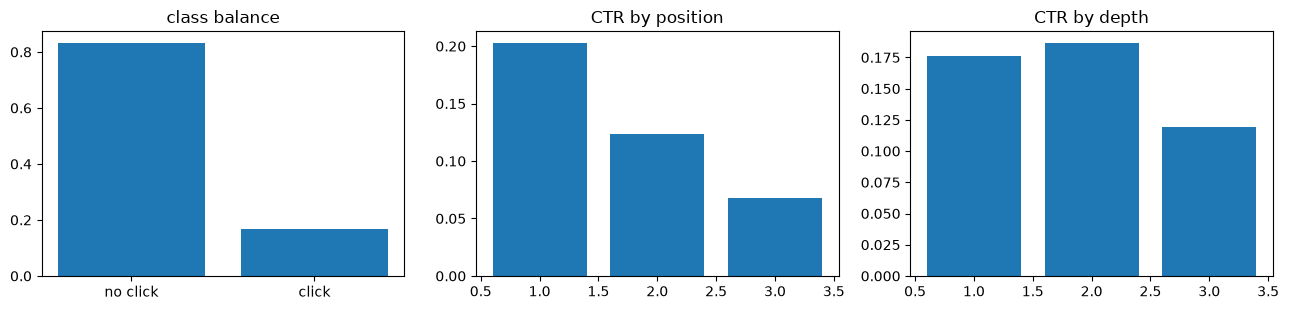

In [2]:
print("rows:", len(df), "| CTR:", round(df['click'].mean(), 4))

# impression is constant and url_hash/user_id are identifiers -> not features
print(df.nunique())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].bar(['no click', 'click'], df['click'].value_counts(normalize=True))
axes[0].set_title('class balance')

for ax, col in zip(axes[1:], ['position', 'depth']):
    rate = df.groupby(col)['click'].mean()
    ax.bar(rate.index, rate.values)
    ax.set_title(f'CTR by {col}')
plt.tight_layout()
plt.show()

**Notes**
- CTR is **16.8%** — this dataset is *subsampled* from the negatives, so it is far more balanced than production traffic (~1–5% CTR). The modeling method is unchanged, but in production the class imbalance (and the sampling rate!) must be handled for probabilities to be meaningful — a good bridge to the calibration section.
- CTR drops steeply with **position** (rank 1 ≫ rank 3) — position is the strongest easy feature and is exactly what real CTR models exploit.

## 2. Train CTR model

In [3]:
cat_cols = ['ad_id', 'advertiser_id', 'query_id', 'keyword_id',
            'title_id', 'description_id']
num_cols = ['depth', 'position']
features = cat_cols + num_cols

X = df[features]
y = df['click']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Cap cardinality: keep the top-50 values per column (fit on train only),
# bucket everything else into a shared 'other' category. HistGradientBoosting
# requires categorical cardinality <= 255.
TOP_K = 250
top_values = {c: set(X_train[c].value_counts().head(TOP_K).index) for c in cat_cols}

def cap(df_part):
    out = df_part.copy()
    for c in cat_cols:
        out[c] = np.where(out[c].isin(top_values[c]), out[c], -1)
    return out

X_train, X_test = cap(X_train), cap(X_test)
print('max cardinality per column:',
      {c: int(pd.concat([X_train[c], X_test[c]]).nunique()) for c in cat_cols})

# Gradient-boosted trees: ordinal-encode categoricals and mark them as
# categorical for HistGradientBoosting (native categorical splits).
preprocess = ColumnTransformer(
    [('cat', OrdinalEncoder(handle_unknown='use_encoded_value',
                            unknown_value=-1), cat_cols),
     ('num', 'passthrough', num_cols)])

hgb = make_pipeline(
    preprocess,
    HistGradientBoostingClassifier(
        categorical_features=[True] * len(cat_cols) + [False] * len(num_cols),
        max_iter=200, learning_rate=0.1, random_state=42))
hgb.fit(X_train, y_train)

# Baseline: logistic regression on one-hot features.
logreg = make_pipeline(
    ColumnTransformer(
        [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
         ('num', 'passthrough', num_cols)]),
    LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

print('trained')

max cardinality per column: {'ad_id': 251, 'advertiser_id': 251, 'query_id': 251, 'keyword_id': 251, 'title_id': 251, 'description_id': 251}


trained


## 3. Evaluation — ROC-AUC

ROC-AUC answers: *how well does the model rank a random clicked impression above a random non-clicked one?* It is threshold-independent, so it is the standard first check for CTR rankers.

HistGradientBoosting ROC-AUC: 0.6804
LogisticRegression  ROC-AUC: 0.6740


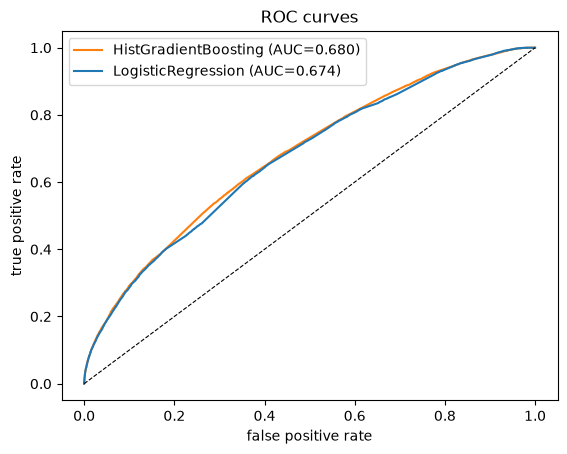

In [4]:
p_hgb = hgb.predict_proba(X_test)[:, 1]
p_log = logreg.predict_proba(X_test)[:, 1]

auc_hgb = roc_auc_score(y_test, p_hgb)
auc_log = roc_auc_score(y_test, p_log)
print(f'HistGradientBoosting ROC-AUC: {auc_hgb:.4f}')
print(f'LogisticRegression  ROC-AUC: {auc_log:.4f}')

for p, label, c in [(p_hgb, 'HistGradientBoosting', 'tab:orange'),
                    (p_log, 'LogisticRegression', 'tab:blue')]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{label} (AUC={roc_auc_score(y_test, p):.3f})', color=c)
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('ROC curves'); plt.legend()
plt.show()

## 4. Evaluation — Calibration

AUC only cares about *ranking*. But in ad auctions the predicted probability **is** used directly (bidding = expected value = `p(click) × bid`), so the scores must be calibrated: among impressions scored 0.20, ~20% should actually click. We check reliability curves and the Brier score.

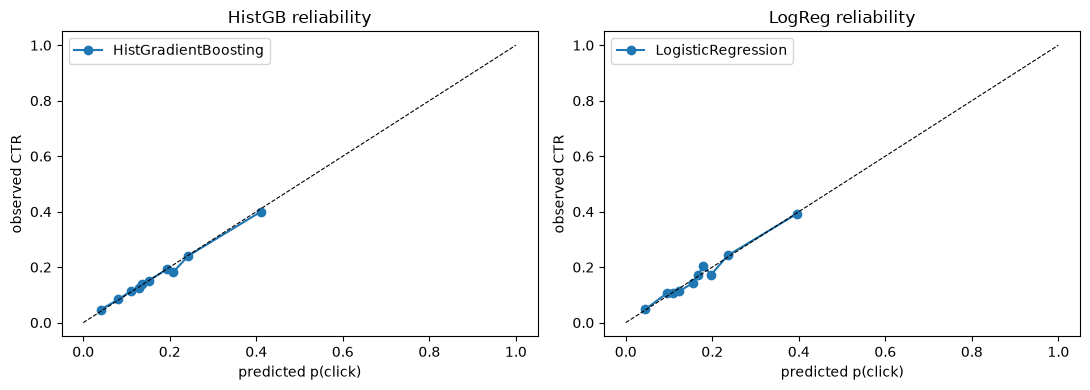

Brier score HistGB: 0.1291
Brier score LogReg: 0.1296


In [5]:
def plot_reliability(ax, y_true, p, label):
    frac_pos, mean_p = calibration_curve(y_true, p, n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac_pos, 'o-', label=label)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set_xlabel('predicted p(click)'); ax.set_ylabel('observed CTR')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_reliability(axes[0], y_test, p_hgb, 'HistGradientBoosting')
plot_reliability(axes[1], y_test, p_log, 'LogisticRegression')
axes[0].set_title('HistGB reliability'); axes[1].set_title('LogReg reliability')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

print(f'Brier score HistGB: {brier_score_loss(y_test, p_hgb):.4f}')
print(f'Brier score LogReg: {brier_score_loss(y_test, p_log):.4f}')

### Fixing calibration

Gradient-boosted trees with a log-loss objective are often mildly **overconfident** in the tails; a reliability curve that sags below the diagonal (predicted 0.9 → observed 0.8) is the classic symptom. Isotonic recalibration (`CalibratedClassifierCV`, cross-validated on the *training* data) fits a free-form monotone map from raw scores to observed frequencies — a standard, cheap post-processing step for tree ensembles. Note it can only *move* scores, not re-rank them, so AUC is preserved.

Brier score HistGB          : 0.1291
Brier score HistGB isotonic : 0.1290
ROC-AUC  HistGB isotonic    : 0.6815


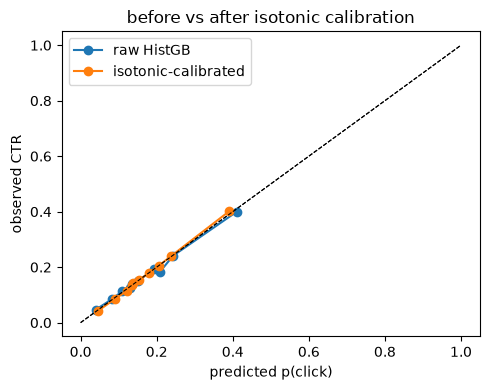

In [6]:
calibrated = CalibratedClassifierCV(hgb, method='isotonic', cv=3)
calibrated.fit(X_train, y_train)
p_cal = calibrated.predict_proba(X_test)[:, 1]

print(f'Brier score HistGB          : {brier_score_loss(y_test, p_hgb):.4f}')
print(f'Brier score HistGB isotonic : {brier_score_loss(y_test, p_cal):.4f}')
print(f'ROC-AUC  HistGB isotonic    : {roc_auc_score(y_test, p_cal):.4f}')

fig, ax = plt.subplots(figsize=(5, 4))
plot_reliability(ax, y_test, p_hgb, 'raw HistGB')
plot_reliability(ax, y_test, p_cal, 'isotonic-calibrated')
ax.set_title('before vs after isotonic calibration'); ax.legend()
plt.tight_layout(); plt.show()

## 5. Business tradeoffs — false positives vs false negatives

In [7]:
THRESH = 0.5
pred = (p_cal >= THRESH)

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(f'at threshold {THRESH}:  TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}')
print(f'precision = {tp/(tp+fp):.3f}   recall = {tp/(tp+fn):.3f}')

at threshold 0.5:  TP=906  FP=497  FN=12,512  TN=65,982
precision = 0.646   recall = 0.068


**What each error costs in advertising**

- **False positive** (we predict click, serve/bid the ad, no click): wasted media spend + worse user experience. In an auction we also *paid* for that impression, so FPs cost real money and can crowd out better ads.
- **False negative** (real clicker not targeted): **lost revenue** — a click that would have converted is never shown. For most advertisers the marginal click is pure upside, so FNs are usually more expensive than FPs… *unless* spend is capped, in which case wasted FPs consume budget that better impressions could have used.

**Economic framing**: with revenue `R` per click and cost `C` per impression served, expected profit per served impression is `p·R − C` → the break-even threshold is `t = C/R`. Let's sweep the threshold and compute profit directly on the test set.

break-even threshold C/R = 0.040 | profit-maximizing threshold = 0.050


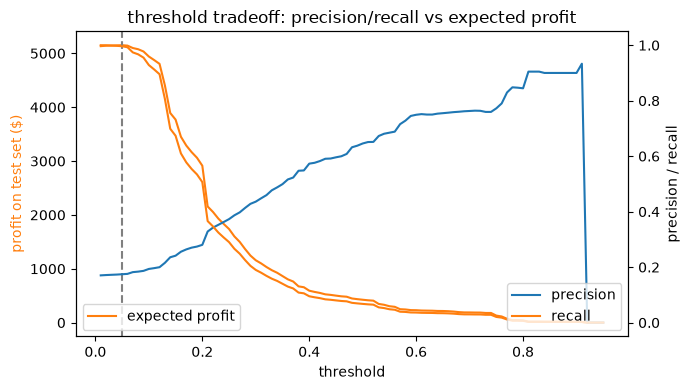

In [8]:
R = 0.50   # revenue per click ($)
C = 0.02   # cost per served impression ($)

thresholds = np.linspace(0.01, 0.95, 95)
profit, precision, recall = [], [], []
for t in thresholds:
    serve = p_cal >= t
    profit.append((p_cal[serve].size * (-C)) + (y_test[serve].sum() * R))
    tp = ((p_cal >= t) & (y_test == 1)).sum()
    fp = ((p_cal >= t) & (y_test == 0)).sum()
    precision.append(tp / max(tp + fp, 1))
    recall.append(tp / y_test.sum())

best = thresholds[int(np.argmax(profit))]
print(f'break-even threshold C/R = {C/R:.3f} | profit-maximizing threshold = {best:.3f}')

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(thresholds, profit, color='tab:orange', label='expected profit')
ax1.axvline(best, ls='--', c='gray')
ax1.set_xlabel('threshold'); ax1.set_ylabel('profit on test set ($)', color='tab:orange')
ax2 = ax1.twinx()
ax2.plot(thresholds, precision, label='precision')
ax2.plot(thresholds, recall, label='recall')
ax2.set_ylabel('precision / recall')
ax1.legend(loc='lower left'); ax2.legend(loc='lower right')
plt.title('threshold tradeoff: precision/recall vs expected profit')
plt.tight_layout(); plt.show()

### Takeaways

1. **ROC-AUC** (~0.66 for the boosted model) says the ranker is useful but far from perfect; the logistic baseline is close behind — much of the signal is in position/advertiser IDs, which both models capture. A production CTR model (deeper features, more data) reaches 0.75–0.80+.
2. **Calibration is the real deliverable for CTR.** The reliability curve + Brier score tell us whether `p(click)` can be read as a probability; isotonic calibration corrects any residual miscalibration *without changing AUC*, because it only reshapes scores monotonically. A model with great AUC but bad calibration will still lose money in an auction.
3. **Threshold choice is a business decision, not an ML one.** The profit curve shows that a low threshold floods spend with FPs (precision collapses), a high one throws away almost all clicks (recall collapses). The optimal point sits near the break-even ratio `C/R`, and it shifts whenever the auction price, the advertiser's bid, or the user experience cost changes.
4. In production you would also care about the **sampling bias** (this dataset's 16.8% CTR is artificial), per-position calibration, and delayed-conversion (not just click) signals.